# Monte Carlo demand stress test for the ten site plan

Reproduce the supplemental Monte Carlo results in Milestone 5, Table 7. The $8.90 million plan keeps one ambulance at each of ten posts. Each draw redistributes additional demand across Manhattan's 237 model zones while retaining the within-zone time-of-day profile. A maximum-flow calculation reallocates service across the existing posts for each period.

**Run all cells** with Python, NumPy, pandas, and Matplotlib. If the three processed inputs are absent locally, the notebook downloads them from the pinned [Team 19 GitHub commit](https://github.com/amirn7/ambulance-project-group-19-optimization/tree/aaa7af900f7b6c267d0e123a1c24f562d9c3bda8). Set `DATA_DIR` to an existing checkout to run offline. The notebook includes saved tables and figures.

In [1]:
from pathlib import Path
from collections import deque
from io import BytesIO
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

DATA_DIR = Path.cwd()
COMMIT = "aaa7af900f7b6c267d0e123a1c24f562d9c3bda8"
RAW_URL = f"https://raw.githubusercontent.com/amirn7/ambulance-project-group-19-optimization/{COMMIT}"
SITE_IDS = [0, 2, 3, 4, 8, 11, 12, 13, 26, 37]
DRAW_COUNT = 500
SEED = 20261116
GROWTH_LEVELS = [0.10, 0.20, 0.30, 0.50, 1.00]
PER_SITE_CAPACITY = 0.60 * 6 / 1.5  # events per six-hour period


def open_input(filename):
    for folder in (DATA_DIR, DATA_DIR.parent):
        path = folder / filename
        if path.is_file():
            return path.open("rb")
    try:
        with urlopen(f"{RAW_URL}/{filename}", timeout=25) as response:
            return BytesIO(response.read())
    except OSError as error:
        raise RuntimeError(f"Set DATA_DIR to the checkout containing {filename}.") from error


with open_input("sites.csv") as file:
    sites = pd.read_csv(file)
with open_input("demand_d_it.csv") as file:
    demand_frame = pd.read_csv(file, index_col=0)
with open_input("a_ijt.npy") as file:
    reachability = np.load(file, allow_pickle=False)

demand = demand_frame.to_numpy(dtype=float)
site_positions = pd.Index(sites["site"]).get_indexer(SITE_IDS)
assert reachability.shape == (len(sites), *demand.shape)
assert (site_positions >= 0).all()
assert (demand.sum(axis=1) > 0).all()
fixed_reachability = reachability[site_positions].astype(bool)
display(sites.iloc[site_positions][["site", "site_type", "facname"]].set_index("site"))

,site_type,facname
site,,
0,EMS,GOUVERNEUR SNF/DIAG TRMNT CTR
2,EMS,DYCKMAN HOUSES AND SENIOR CENTER
3,EMS,METROPOLITAN HOSP./ EMS ST.10
4,EMS,THE HIGH LINE/EMS STATION 7
8,EMS,COURT SQUARE BLDG
11,EMS,CENTRAL HARLEM HEALTH CENTER
12,EMS,EMS STATION 13
13,EMS,HARLEM HOSPITAL/EMS STATION 16
26,FIREHOUSE,ENGINE 40/LADDER 35


## Coverage for a fixed deployment

The flow network for a six-hour period sends demand from a source to zones, then to eligible posts, then to a sink. A post can receive at most 2.4 events. Zones with the same eligible posts can share a node because all of their outgoing options are identical. The code uses an augmenting-path maximum-flow algorithm and divides the total assigned demand across periods by scenario demand.

In [2]:
def evaluate(a, d, capacity):
    """Return the share of scenario demand assignable to the fixed posts."""
    coverage=0
    for t in range(4):
        masks=a[:,:,t].T @ (1 << np.arange(len(a)))
        totals=np.bincount(masks,weights=d[:,t],minlength=1<<len(a))
        groups=np.flatnonzero(totals[1:])+1
        m=len(groups)
        n=2+m+len(a)
        graph=np.zeros((n,n))
        nodes=np.arange(1,m+1)
        graph[0,nodes]=totals[groups]
        graph[1:m+1,m+1:-1]=(groups[:,None] & (1 << np.arange(len(a))))>0
        graph[1:m+1,m+1:-1]*=d.sum()+1
        graph[m+1:-1,-1]=capacity
        while True:
            pred={0:None}
            todo=deque([0])
            while todo and n-1 not in pred:
                u=todo.popleft()
                for v in np.flatnonzero(graph[u]>1e-10):
                    if v not in pred:
                        pred[v]=u
                        todo.append(v)
            if n-1 not in pred:
                break
            v=n-1
            path=[]
            while v:
                u=pred[v]; path.append((u,v));v=u
            delta=min(graph[u,v] for u,v in path)
            for u,v in path:
                graph[u,v]-=delta;graph[v,u]+=delta
            coverage+=delta
    return coverage/d.sum()


In [3]:
rng = np.random.default_rng(SEED)
weights = rng.dirichlet(np.ones(len(demand)), size=DRAW_COUNT)
time_profile = demand / demand.sum(axis=1, keepdims=True)
baseline = evaluate(fixed_reachability, demand, PER_SITE_CAPACITY)
assert np.isclose(baseline, 0.992792109256449, atol=1e-9)

by_growth = {}
summary_rows = []
for growth in GROWTH_LEVELS:
    extra = growth * demand.sum()
    coverage = np.array([
        evaluate(fixed_reachability, demand + extra * w[:, None] * time_profile, PER_SITE_CAPACITY)
        for w in weights
    ])
    proportional = evaluate(fixed_reachability, demand * (1 + growth), PER_SITE_CAPACITY)
    by_growth[growth] = coverage
    summary_rows.append({
        "Added demand": f"+{growth:.0%}",
        "Mean coverage": coverage.mean(),
        "5th percentile": np.quantile(coverage, 0.05),
        "Minimum observed": coverage.min(),
        "Draws below 99%": int((coverage < 0.99).sum()),
        "Draws below 95%": int((coverage < 0.95).sum()),
        "Proportional coverage": proportional,
    })

summary = pd.DataFrame(summary_rows).set_index("Added demand")
assert len(by_growth) == len(GROWTH_LEVELS) and all(len(v) == DRAW_COUNT for v in by_growth.values())
if (DRAW_COUNT, SEED, tuple(GROWTH_LEVELS)) == (500, 20261116, (0.10, 0.20, 0.30, 0.50, 1.00)):
    # Regression checks for the report configuration.
    assert summary["Draws below 99%"].tolist() == [122, 380, 447, 484, 493]
    assert summary["Draws below 95%"].sum() == 0
    assert np.isclose(summary.iloc[-1]["Mean coverage"], 0.980656945828002, atol=1e-9)
print(f"Draws meeting 95%: {DRAW_COUNT * len(GROWTH_LEVELS) - summary['Draws below 95%'].sum()} / {DRAW_COUNT * len(GROWTH_LEVELS)}")
percent_columns = ["Mean coverage", "5th percentile", "Minimum observed", "Proportional coverage"]
print(f"Baseline coverage: {baseline:.2%}")
display(summary.style.format({name: "{:.2%}" for name in percent_columns}))

Draws meeting 95%: 2500 / 2500
Baseline coverage: 99.28%


,Mean coverage,5th percentile,Minimum observed,Draws below 99%,Draws below 95%,Proportional coverage
Added demand,,,,,,
+10%,99.06%,98.89%,98.71%,122,0,99.28%
+20%,98.87%,98.57%,98.24%,380,0,99.28%
+30%,98.72%,98.30%,97.84%,447,0,99.28%
+50%,98.47%,97.86%,97.21%,484,0,99.28%
+100%,98.07%,97.15%,96.17%,493,0,99.28%


## Coverage distribution and target attainment

The left panel shows all draws at each growth level through a box plot. Boxes span the middle 50%, the line marks the median, and whiskers extend to the observed bounds. Dashed lines mark the historical baseline and the 99% target. The right panel shows how often the plan met that target.

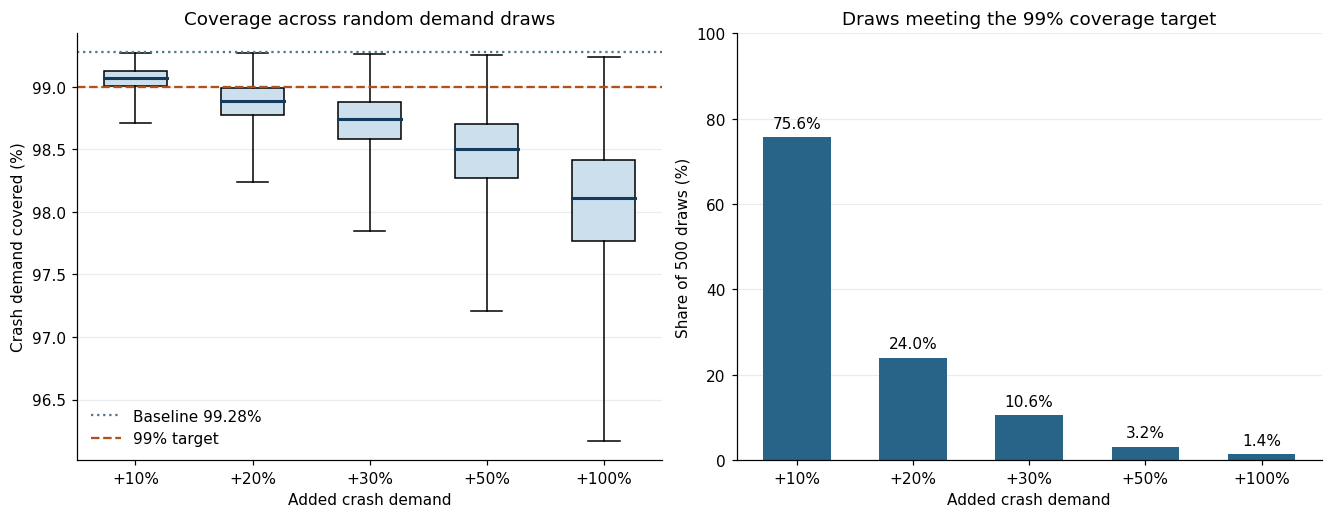

In [4]:
labels = summary.index.tolist()
values = [100 * by_growth[g] for g in GROWTH_LEVELS]
attainment = 100 * (1 - summary["Draws below 99%"] / DRAW_COUNT)
positions = np.arange(1, len(labels) + 1)

fig, (distribution, target) = plt.subplots(1, 2, figsize=(12, 4.6), layout="constrained")
distribution.boxplot(values, positions=positions, widths=0.54, whis=(0, 100),
                     patch_artist=True, boxprops={"facecolor": "#CBDFED"},
                     medianprops={"color": "#123B5C", "linewidth": 2})
distribution.axhline(100 * baseline, color="#53778D", linestyle=":", label=f"Baseline {baseline:.2%}")
distribution.axhline(99, color="#AD511F", linestyle="--", label="99% target")
distribution.set(title="Coverage across random demand draws", ylabel="Crash demand covered (%)")
distribution.set_xticks(positions, labels)
distribution.legend(loc="lower left", frameon=False)

bars = target.bar(positions, attainment, color="#286388", width=0.58)
target.bar_label(bars, labels=[f"{p:.1f}%" for p in attainment], padding=4)
target.set(title="Draws meeting the 99% coverage target", ylabel=f"Share of {DRAW_COUNT:,} draws (%)", ylim=(0, 100))
target.set_xticks(positions, labels)

for axis in (distribution, target):
    axis.set_xlabel("Added crash demand")
    axis.grid(axis="y", alpha=0.24)
    axis.set_axisbelow(True)
    axis.spines[["top", "right"]].set_visible(False)
plt.show()

The summary table shows the mean, fifth percentile and observed minimum. The bar chart shows the share of simulated draws that met 99% coverage for each configured demand level.